# Delivery Time Prediction with TabPFN-3.5 (Google Colab T4)

This notebook runs the full-test evaluation of TabPFN-3.5 (tabpfn 10.2.0) on the Meituan delivery dataset using a Google Colab NVIDIA T4 GPU. It uses `data/dataloader.py` and `models/tabpfn_model.py`.

**v2 settings** (see `docs/5_relatorio_tabpfn.md`): a single TabPFN member with a large context (`TRAIN_SAMPLE_SIZE=50,000`) instead of `5x5,000` subsamples, `fit_mode='fit_with_cache'` (the training context is encoded once and reused for every test batch), `output_type='median'` (optimal for MAE), `district_id` declared as categorical, automatic batch-size halving on CUDA OOM, a TabPFN-vs-LightGBM learning curve and a TabPFN + LightGBM blend.

Results of the previous `5x5,000` / `fit_preprocessors` run are preserved in git commit `9eef1f2` and summarized in `docs/5_relatorio_tabpfn.md`.

## Stage 0: Colab Setup, Bundle Upload, and Authentication

Before running, select Runtime -> Change runtime type -> T4 GPU and add `TABPFN_TOKEN` to Colab Secrets (key icon on the left sidebar). When prompted, upload `meituan_colab_bundle.zip` (no GitHub account or token required).

In [3]:
import os
import subprocess
import sys
import zipfile
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
WORK_ROOT = Path('/content/meituan-project')
DRIVE_PROJECT_DIR = ''  # Optional: set to '/content/drive/MyDrive/...' if using Google Drive

if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tabpfn==10.2.0', 'pyarrow', 'lightgbm'], check=True)

    if DRIVE_PROJECT_DIR and Path(DRIVE_PROJECT_DIR).exists():
        WORK_ROOT = Path(DRIVE_PROJECT_DIR)
    elif not (WORK_ROOT / 'data' / 'dataloader.py').exists():
        WORK_ROOT.mkdir(parents=True, exist_ok=True)
        local_zip = Path('/content/meituan_colab_bundle.zip')
        if not local_zip.exists():
            from google.colab import files
            print('Please select meituan_colab_bundle.zip to upload:')
            uploaded = files.upload()
            zip_names = [k for k in uploaded if k.endswith('.zip')]
            if not zip_names:
                raise RuntimeError('No .zip bundle uploaded.')
            local_zip = Path('/content') / zip_names[0]
        with zipfile.ZipFile(local_zip, 'r') as zf:
            zf.extractall(WORK_ROOT)

    nb_dir = WORK_ROOT / 'notebooks_analysis'
    nb_dir.mkdir(parents=True, exist_ok=True)
    os.chdir(nb_dir)

    if not os.environ.get('TABPFN_TOKEN'):
        try:
            from google.colab import userdata
            token = userdata.get('TABPFN_TOKEN')
            if token:
                os.environ['TABPFN_TOKEN'] = token.strip()
        except Exception:
            pass

    if not os.environ.get('TABPFN_TOKEN'):
        raise RuntimeError('TABPFN_TOKEN not found. Add it to Colab Secrets.')
    print('Colab setup complete. Working dir:', Path.cwd())
else:
    print('Running outside Colab. Working dir:', Path.cwd())

Colab setup complete. Working dir: /content/meituan-project/notebooks_analysis


## Stage 1: Hardware Verification and T4 Configuration

This section verifies CUDA availability and GPU memory, fixes the random seed, imports the shared dataloader and TabPFN wrapper, and configures the inference parameters. `run_with_oom_retry` halves `batch_size` whenever CUDA runs out of memory, so larger contexts can be tried safely.

In [4]:
import gc
import json
import time
import zipfile
from dataclasses import replace

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tabpfn
import torch
from sklearn.ensemble import RandomForestRegressor

sys.path += ['../data', '../models']
from dataloader import (
    BASELINE,
    FEATURES_COMPLETE,
    FEATURES_REDUCED,
    TARGET,
    load_meituan,
)
from tabpfn_model import (
    TabPFNConfig,
    TabPFNModel,
    compute_metrics,
    sample_dataframe,
)

SEED = 42
CKPT_DIR = Path('../models/checkpoints')
CKPT_DIR.mkdir(parents=True, exist_ok=True)
HAS_CUDA = torch.cuda.is_available()

if HAS_CUDA:
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'GPU: {gpu_name} ({vram_gb:.1f} GB VRAM)')
    # One member with a large context beats many 5k subsamples: in the v1 run the
    # 5x5,000 ensemble plateaued after 3 members (MAE 5.564 -> 5.526).
    TRAIN_SAMPLE_SIZE = 50_000
    N_ENSEMBLE = 1
    N_ESTIMATORS = 'auto'
    # KV-cache of the training context (~4 GB / 1M rows / estimator per Prior Labs),
    # so the context is not re-encoded for every test batch as with 'fit_preprocessors'.
    FIT_MODE = 'fit_with_cache'
    BATCH_SIZE = 8192
    TEST_EVAL_SIZE = None
    LEARNING_CURVE_SIZES = [5_000, 20_000, 50_000, 100_000, 200_000]
    LC_EVAL_SIZE = 20_000  # stratified test subset for the learning curve (speed)
else:
    print('Warning: CUDA GPU not detected; falling back to CPU profile (TabPFN-3.5 caps CPU at 5,000 rows).')
    TRAIN_SAMPLE_SIZE = 3000
    N_ENSEMBLE = 3
    N_ESTIMATORS = 8
    FIT_MODE = 'fit_with_cache'
    BATCH_SIZE = 4096
    TEST_EVAL_SIZE = 2000
    LEARNING_CURVE_SIZES = [1_000, 3_000]
    LC_EVAL_SIZE = 2000

OUTPUT_TYPE = 'median'             # median minimises MAE; use 'mean' to optimise RMSE
CATEGORICAL_COLS = ('district_id',)  # identifier, not an ordinal quantity

SAVE_JOBLIB_CHECKPOINTS = False  # Set True if you need full .joblib checkpoints on disk


def run_with_oom_retry(fn, cfg, min_batch=256):
    """Call fn(cfg); on CUDA OOM free memory, halve cfg.batch_size and retry."""
    bs = cfg.batch_size
    while True:
        try:
            return fn(replace(cfg, batch_size=bs))
        except torch.cuda.OutOfMemoryError:
            gc.collect()
            if HAS_CUDA:
                torch.cuda.empty_cache()
            if bs // 2 < min_batch:
                raise
            bs //= 2
            print(f'[OOM] retrying with batch_size={bs}')


def free_gpu():
    gc.collect()
    if HAS_CUDA:
        torch.cuda.empty_cache()


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f'tabpfn={tabpfn.__version__} | sample={N_ENSEMBLE}x{TRAIN_SAMPLE_SIZE} | '
      f'fit_mode={FIT_MODE} | batch_size={BATCH_SIZE} | output={OUTPUT_TYPE} | '
      f'test_eval={TEST_EVAL_SIZE or "FULL"}')

GPU: Tesla T4 (15.6 GB VRAM)
tabpfn=10.2.0 | sample=1x50000 | fit_mode=fit_with_cache | batch_size=8192 | output=median | test_eval=FULL


## Stage 2: Data Loading (Full Test Partitions)

We load the `70_30`, `stratified_district`, and `district` partitions with `distance='manhattan'`. On GPU, `TEST_EVAL_SIZE=None` evaluates every row in each official test split (53,872 rows for `70_30` and `stratified_district`; 79,023 rows for `district`).

In [5]:
SPLIT_NAMES = ['70_30', 'stratified_district', 'district']
splits = {}
summary_rows = []

for split_name in SPLIT_NAMES:
    tr_df, val_df, te_df = load_meituan(
        split=split_name,
        distance='manhattan',
        seed=SEED,
        verbose=False,
    )
    tr_df = tr_df.copy()
    te_df = te_df.copy()
    tr_df['_y_bin'] = pd.qcut(tr_df[TARGET], q=20, labels=False, duplicates='drop')
    te_df['_y_bin'] = pd.qcut(te_df[TARGET], q=20, labels=False, duplicates='drop')

    te_eval, _, te_hash = sample_dataframe(
        te_df, TEST_EVAL_SIZE, stratify_col='_y_bin', seed=SEED
    )
    strat_col = 'district_id' if split_name == 'stratified_district' else '_y_bin'
    splits[split_name] = {
        'train': tr_df,
        'val': val_df,
        'test_eval': te_eval,
        'test_eval_sha256': te_hash,
        'stratify_col': strat_col,
    }
    summary_rows.append({
        'split': split_name,
        'train_rows': len(tr_df),
        'test_eval_rows': len(te_eval),
        'test_target_var': round(float(np.var(te_eval[TARGET])), 2),
        'test_target_mean_min': round(float(te_eval[TARGET].mean()), 3),
    })

pd.DataFrame(summary_rows)

,split,train_rows,test_eval_rows,test_target_var,test_target_mean_min
0,70_30,377104,53872,139.68,29.498
1,stratified_district,377104,53872,139.06,29.445
2,district,380518,79023,120.85,29.341


## Stage 3: Platform Baseline Reference

We compute the error metrics of the Meituan platform arrival estimate (`meituan_baseline_min`) on each test set.

In [6]:
baseline_rows = []
for split_name, part in splits.items():
    te_eval = part['test_eval']
    m = compute_metrics(te_eval[TARGET], te_eval[BASELINE])
    baseline_rows.append({
        'split': split_name,
        'stage': 'platform_baseline',
        'model': 'Meituan App Estimate',
        'test_MAE': round(m['MAE'], 3),
        'test_RMSE': round(m['RMSE'], 3),
        'test_R2': round(m['R2'], 4),
        'runtime_s': 0.0,
    })

baseline_df = pd.DataFrame(baseline_rows)
baseline_df

,split,stage,model,test_MAE,test_RMSE,test_R2,runtime_s
0,70_30,platform_baseline,Meituan App Estimate,9.535,11.646,0.0291,0.0
1,stratified_district,platform_baseline,Meituan App Estimate,9.524,11.629,0.0276,0.0
2,district,platform_baseline,Meituan App Estimate,9.401,11.616,-0.1166,0.0


## Stage 4: Full-Test TabPFN-3.5 Evaluation and Audit Manifests

This stage evaluates TabPFN-3.5 across `70_30` (checkout and dispatch), `stratified_district` (dispatch), and `district` (dispatch), saving per-scenario predictions, logs, and SHA-256 audit manifests while clearing GPU memory between runs. For the reference scenario (`70_30` / `complete_dispatch`) it also stores mean-output predictions (mean vs median comparison), per-member predictions (ensemble curve, no refit needed in Stage 5) and validation predictions (blend weight).

In [7]:
SCENARIOS = [
    ('70_30', 'reduced_checkout', FEATURES_REDUCED),
    ('70_30', 'complete_dispatch', FEATURES_COMPLETE),
    ('stratified_district', 'complete_dispatch', FEATURES_COMPLETE),
    ('district', 'complete_dispatch', FEATURES_COMPLETE),
]
REFERENCE_SCENARIO = ('70_30', 'complete_dispatch')

BASE_CONFIG = TabPFNConfig(
    model_version='v3.5',
    n_ensemble=N_ENSEMBLE,
    sample_size=TRAIN_SAMPLE_SIZE,
    sampling_strategy='stratified',
    n_estimators=N_ESTIMATORS,
    fit_mode=FIT_MODE,
    n_preprocessing_jobs=1,
    batch_size=BATCH_SIZE,
    aggregation='mean',
    output_type=OUTPUT_TYPE,
    categorical_cols=CATEGORICAL_COLS,
    ignore_pretraining_limits=True,
    seed=SEED,
    device='auto',
    verbose=True,
)
TABPFN_LABEL = f'TabPFN-{BASE_CONFIG.model_version} ({N_ENSEMBLE}x{TRAIN_SAMPLE_SIZE:,}, {OUTPUT_TYPE})'

experiment_rows = []
audit_rows = []
predictions_store = {}
reference_extra = {}

for split_name, stage_name, feat_cols in SCENARIOS:
    part = splits[split_name]
    tr_df = part['train']
    te_eval = part['test_eval']
    tag = f'colab_{split_name}_{stage_name}'
    is_ref = (split_name, stage_name) == REFERENCE_SCENARIO
    print(f'\n--- Running {tag} ({len(feat_cols)} features on {len(te_eval):,} test rows) ---')

    def _fit_and_predict(cfg):
        mdl = TabPFNModel(cfg).fit(
            tr_df,
            tr_df[TARGET],
            num_cols=feat_cols,
            stratify_col=part['stratify_col'],
            log_path=CKPT_DIR / f'{tag}_log.csv',
        )
        return mdl, mdl.predict_members(te_eval)

    t0 = time.time()
    model, member_preds = run_with_oom_retry(_fit_and_predict, BASE_CONFIG)
    stacked = np.vstack(member_preds)
    test_preds, test_std = stacked.mean(axis=0), stacked.std(axis=0)
    test_metrics = compute_metrics(te_eval[TARGET], test_preds)
    model.record_eval_target(te_eval[TARGET])
    elapsed = round(time.time() - t0, 1)

    if is_ref:
        # Extra inference for Stage 5 (not counted in runtime_s above).
        reference_extra['member_preds'] = member_preds
        reference_extra['test_mean_output'] = model.predict(te_eval, output_type='mean')
        reference_extra['val_preds'] = model.predict(part['val'])

    if SAVE_JOBLIB_CHECKPOINTS:
        model.save(CKPT_DIR / f'{tag}.joblib', extra={'split': split_name, 'stage': stage_name, 'test_metrics': test_metrics})

    manifest = model.save_audit_manifest(
        CKPT_DIR / f'{tag}_audit.json',
        extra={
            'split': split_name,
            'stage': stage_name,
            'distance': 'manhattan',
            'test_eval_sha256': part['test_eval_sha256'],
            'test_metrics': test_metrics,
            'runtime_s': elapsed,
        },
    )

    pd.DataFrame({
        'y_true': te_eval[TARGET].to_numpy(),
        'y_pred': test_preds,
        'y_std': test_std,
    }).to_parquet(CKPT_DIR / f'{tag}_predictions.parquet', index=False)

    predictions_store[(split_name, stage_name)] = {
        'y_true': te_eval[TARGET].to_numpy(),
        'y_pred': test_preds,
        'y_std': test_std,
    }

    audit_rows.append({
        'scenario': tag,
        'tabpfn_pkg': manifest['packages']['tabpfn'],
        'device': manifest['environment']['device'],
        'fit_mode': manifest['config']['fit_mode'],
        'output_type': manifest['config']['output_type'],
        'train_target_sha256': manifest['train_target_sha256'][:12],
        'eval_target_sha256': manifest['eval_target_sha256'][:12],
    })

    experiment_rows.append({
        'split': split_name,
        'stage': stage_name,
        'model': TABPFN_LABEL,
        'test_MAE': round(test_metrics['MAE'], 3),
        'test_RMSE': round(test_metrics['RMSE'], 3),
        'test_R2': round(test_metrics['R2'], 4),
        'runtime_s': elapsed,
    })

    del model, member_preds, stacked
    free_gpu()

results_df = pd.DataFrame(experiment_rows)
audit_df = pd.DataFrame(audit_rows)
display(results_df)
display(audit_df)


--- Running colab_70_30_reduced_checkout (13 features on 53,872 test rows) ---
TabPFN (v3.5) | ensemble=1 x sample_size=50,000 (stratified) | n_estimators=auto | fit_mode=fit_with_cache | output=median | features=13 (categorical=1) | device=cuda


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

  member  1/1 | n=50,000 | 205.7s
Audit manifest saved to ../models/checkpoints/colab_70_30_reduced_checkout_audit.json

--- Running colab_70_30_complete_dispatch (25 features on 53,872 test rows) ---
TabPFN (v3.5) | ensemble=1 x sample_size=50,000 (stratified) | n_estimators=auto | fit_mode=fit_with_cache | output=median | features=25 (categorical=1) | device=cuda
  member  1/1 | n=50,000 | 204.9s
Audit manifest saved to ../models/checkpoints/colab_70_30_complete_dispatch_audit.json

--- Running colab_stratified_district_complete_dispatch (25 features on 53,872 test rows) ---
TabPFN (v3.5) | ensemble=1 x sample_size=50,000 (stratified) | n_estimators=auto | fit_mode=fit_with_cache | output=median | features=25 (categorical=1) | device=cuda
  member  1/1 | n=50,000 | 205.7s
Audit manifest saved to ../models/checkpoints/colab_stratified_district_complete_dispatch_audit.json

--- Running colab_district_complete_dispatch (25 features on 79,023 test rows) ---
TabPFN (v3.5) | ensemble=1 x s

,split,stage,model,test_MAE,test_RMSE,test_R2,runtime_s
0,70_30,reduced_checkout,"TabPFN-v3.5 (1x50,000, median)",5.784,7.596,0.5869,412.5
1,70_30,complete_dispatch,"TabPFN-v3.5 (1x50,000, median)",5.323,6.962,0.6530,417.2
2,stratified_district,complete_dispatch,"TabPFN-v3.5 (1x50,000, median)",5.319,6.963,0.6513,417.9
3,district,complete_dispatch,"TabPFN-v3.5 (1x50,000, median)",5.706,7.395,0.5475,513.6


,scenario,tabpfn_pkg,device,fit_mode,output_type,train_target_sha256,eval_target_sha256
0,colab_70_30_reduced_checkout,10.2.0,cuda,fit_with_cache,median,72617a3aba5f,51e4e84d68a9
1,colab_70_30_complete_dispatch,10.2.0,cuda,fit_with_cache,median,72617a3aba5f,51e4e84d68a9
2,colab_stratified_district_complete_dispatch,10.2.0,cuda,fit_with_cache,median,5100ed46d943,6e2bf98caa87
3,colab_district_complete_dispatch,10.2.0,cuda,fit_with_cache,median,d1731a32501f,d37c4ebf8b7f


## Stage 5: Sample-Parity, Full-Data Comparison and TabPFN + LightGBM Blend

On the complete `70_30` test set we compare: LightGBM trained on the same `TRAIN_SAMPLE_SIZE` rows as one TabPFN member, TabPFN-3.5 with mean and median output, Random Forest and LightGBM on all 377k rows, and a weighted blend of TabPFN and full LightGBM. The blend weight is chosen on the validation split (never on test). TabPFN predictions are reused from Stage 4, so nothing is refitted.

In [8]:
p70 = splits['70_30']
tr_70, val_70, te_70 = p70['train'], p70['val'], p70['test_eval']
y_te = te_70[TARGET].to_numpy()

# 1. Random Forest (full 377k)
t0 = time.time()
rf_full = RandomForestRegressor(
    n_estimators=50, max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1
).fit(tr_70[FEATURES_COMPLETE], tr_70[TARGET])
m_rf = compute_metrics(y_te, rf_full.predict(te_70[FEATURES_COMPLETE]))
t_rf = round(time.time() - t0, 1)
del rf_full
gc.collect()

# 2. LightGBM (same number of rows as one TabPFN member)
tr_sub, _, _ = sample_dataframe(tr_70, TRAIN_SAMPLE_SIZE, stratify_col='_y_bin', seed=SEED)
t0 = time.time()
lgbm_sub = lgb.LGBMRegressor(
    n_estimators=2000, learning_rate=0.05, num_leaves=31, random_state=SEED, n_jobs=-1, verbose=-1
)
lgbm_sub.fit(
    tr_sub[FEATURES_COMPLETE], tr_sub[TARGET],
    eval_set=[(val_70[FEATURES_COMPLETE], val_70[TARGET])],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
m_lgbm_sub = compute_metrics(y_te, lgbm_sub.predict(te_70[FEATURES_COMPLETE]))
t_lgbm_sub = round(time.time() - t0, 1)

# 3. LightGBM (full 377k)
t0 = time.time()
lgbm_full = lgb.LGBMRegressor(
    n_estimators=2000, learning_rate=0.05, num_leaves=31, random_state=SEED, n_jobs=-1, verbose=-1
)
lgbm_full.fit(
    tr_70[FEATURES_COMPLETE], tr_70[TARGET],
    eval_set=[(val_70[FEATURES_COMPLETE], val_70[TARGET])],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
lgbm_te = lgbm_full.predict(te_70[FEATURES_COMPLETE])
lgbm_val = lgbm_full.predict(val_70[FEATURES_COMPLETE])
m_lgbm_full = compute_metrics(y_te, lgbm_te)
t_lgbm_full = round(time.time() - t0, 1)

# 4. TabPFN from Stage 4 (no refit)
tab_te = predictions_store[REFERENCE_SCENARIO]['y_pred']
tab_val = reference_extra['val_preds']
m_tab = compute_metrics(y_te, tab_te)
m_tab_meanout = compute_metrics(y_te, reference_extra['test_mean_output'])
ref_runtime = float(results_df.query("split == '70_30' and stage == 'complete_dispatch'")['runtime_s'].iloc[0])

# Ensemble-size curve from stored member predictions (only informative if N_ENSEMBLE > 1)
member_preds = reference_extra['member_preds']
ens_curve_df = pd.DataFrame([
    {'member': k, **{f'test_{key.lower()}': v for key, v in
                     compute_metrics(y_te, np.mean(np.vstack(member_preds[:k]), axis=0)).items()}}
    for k in range(1, len(member_preds) + 1)
])
ens_curve_df.to_csv(CKPT_DIR / 'colab_tabpfn_ensemble_curve.csv', index=False)

# 5. Blend: weight chosen on validation MAE. Note LightGBM early-stopped on the same
# validation split, so the chosen weight is slightly optimistic towards LightGBM.
weights = np.round(np.arange(0.0, 1.0001, 0.05), 2)
val_mae = [compute_metrics(val_70[TARGET], w * tab_val + (1 - w) * lgbm_val)['MAE'] for w in weights]
w_best = float(weights[int(np.argmin(val_mae))])
m_blend = compute_metrics(y_te, w_best * tab_te + (1 - w_best) * lgbm_te)
print(f'Blend weight (TabPFN share) chosen on validation: {w_best:.2f}')

def _row(name, rows, m, t):
    return {'model': name, 'train_rows': rows, 'test_MAE': round(m['MAE'], 3),
            'test_RMSE': round(m['RMSE'], 3), 'test_R2': round(m['R2'], 4), 'runtime_s': t}

parity_df = pd.DataFrame([
    _row(f'LightGBM ({TRAIN_SAMPLE_SIZE:,} rows)', TRAIN_SAMPLE_SIZE, m_lgbm_sub, t_lgbm_sub),
    _row(f'TabPFN-v3.5 ({N_ENSEMBLE}x{TRAIN_SAMPLE_SIZE:,}, mean)', N_ENSEMBLE * TRAIN_SAMPLE_SIZE, m_tab_meanout, None),
    _row(TABPFN_LABEL, N_ENSEMBLE * TRAIN_SAMPLE_SIZE, m_tab, ref_runtime),
    _row('Random Forest (377k rows)', len(tr_70), m_rf, t_rf),
    _row('LightGBM (377k rows)', len(tr_70), m_lgbm_full, t_lgbm_full),
    _row(f'Blend TabPFN x{w_best:.2f} + LightGBM', len(tr_70), m_blend, None),
])
parity_df.to_csv(CKPT_DIR / 'colab_tabpfn_parity_comparison.csv', index=False)

free_gpu()
display(parity_df)
display(ens_curve_df)

Blend weight (TabPFN share) chosen on validation: 0.45


,model,train_rows,test_MAE,test_RMSE,test_R2,runtime_s
0,"LightGBM (50,000 rows)",50000,5.477,7.087,0.6405,9.8
1,"TabPFN-v3.5 (1x50,000, mean)",50000,5.354,6.934,0.6557,NaN
2,"TabPFN-v3.5 (1x50,000, median)",50000,5.323,6.962,0.6530,417.2
3,Random Forest (377k rows),377104,5.672,7.325,0.6159,229.4
4,LightGBM (377k rows),377104,5.313,6.879,0.6612,84.1
5,Blend TabPFN x0.45 + LightGBM,377104,5.278,6.856,0.6634,NaN


,member,test_mae,test_rmse,test_r2
0,1,5.322534,6.961727,0.653023


## Stage 5b: Learning Curve (TabPFN-3.5 vs LightGBM at Equal Training Size)

The fair comparison between an in-context learner and a GBDT is the learning curve: both models receive the same stratified training subsample of each size in `LEARNING_CURVE_SIZES` and are evaluated on the same stratified test subset (`LC_EVAL_SIZE` rows). TabPFN uses one member; if CUDA runs out of memory even after batch halving, the remaining TabPFN sizes are skipped and LightGBM continues.

In [10]:
te_lc, _, _ = sample_dataframe(te_70, LC_EVAL_SIZE, stratify_col='_y_bin', seed=SEED)
y_lc = te_lc[TARGET].to_numpy()
lc_rows = []
tabpfn_oom = False

for n in LEARNING_CURVE_SIZES:
    if n > len(tr_70):
        break
    sub, _, _ = sample_dataframe(tr_70, n, stratify_col='_y_bin', seed=SEED)

    t0 = time.time()
    lg = lgb.LGBMRegressor(
        n_estimators=2000, learning_rate=0.05, num_leaves=31, random_state=SEED, n_jobs=-1, verbose=-1
    ).fit(
        sub[FEATURES_COMPLETE], sub[TARGET],
        eval_set=[(val_70[FEATURES_COMPLETE], val_70[TARGET])],
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    lc_rows.append({'n_train': n, 'model': 'LightGBM',
                    **compute_metrics(y_lc, lg.predict(te_lc[FEATURES_COMPLETE])),
                    'runtime_s': round(time.time() - t0, 1)})

    if tabpfn_oom:
        continue
    cfg_n = replace(BASE_CONFIG, n_ensemble=1, sample_size=n, verbose=False)
    t0 = time.time()
    def _fit_predict_lc(c):
        # Refit on retry is cheap (fit < 1 s); predict then uses the halved batch_size.
        mdl = TabPFNModel(c).fit(sub, sub[TARGET], num_cols=FEATURES_COMPLETE, stratify_col=None)
        return mdl.predict(te_lc)

    try:
        pred = run_with_oom_retry(_fit_predict_lc, cfg_n)
        lc_rows.append({'n_train': n, 'model': 'TabPFN-v3.5',
                        **compute_metrics(y_lc, pred), 'runtime_s': round(time.time() - t0, 1)})
    except torch.cuda.OutOfMemoryError:
        print(f'[OOM] TabPFN does not fit on this GPU with n_train={n:,}; skipping larger sizes.')
        tabpfn_oom = True
    free_gpu()
    print(f'n_train={n:>7,} done')

lc_df = pd.DataFrame(lc_rows).round({'MAE': 3, 'RMSE': 3, 'R2': 4})
lc_df.to_csv(CKPT_DIR / 'colab_tabpfn_learning_curve.csv', index=False)
display(lc_df.pivot(index='n_train', columns='model', values='MAE'))

[OOM] retrying with batch_size=4096
[OOM] retrying with batch_size=2048
[OOM] retrying with batch_size=1024
[OOM] retrying with batch_size=512
[OOM] retrying with batch_size=256
[OOM] TabPFN does not fit on this GPU with n_train=5,000; skipping larger sizes.
n_train=  5,000 done


model,LightGBM
n_train,
5000,5.785
20000,5.581
50000,5.493
100000,5.417
200000,5.363


## Stage 6: Results Summary, Plots, and Artifact Export

This final stage saves consolidated tables, renders diagnostic plots (model comparison, learning curve, predicted vs actual), and packages all CSV, JSON, Parquet, and PNG outputs into `tabpfn_colab_artifacts.zip` for download.

,split,stage,model,test_MAE,test_RMSE,test_R2,runtime_s
0,70_30,complete_dispatch,"TabPFN-v3.5 (1x50,000, median)",5.323,6.962,0.6530,417.2
1,70_30,platform_baseline,Meituan App Estimate,9.535,11.646,0.0291,0.0
2,70_30,reduced_checkout,"TabPFN-v3.5 (1x50,000, median)",5.784,7.596,0.5869,412.5
3,district,complete_dispatch,"TabPFN-v3.5 (1x50,000, median)",5.706,7.395,0.5475,513.6
4,district,platform_baseline,Meituan App Estimate,9.401,11.616,-0.1166,0.0
5,stratified_district,complete_dispatch,"TabPFN-v3.5 (1x50,000, median)",5.319,6.963,0.6513,417.9
6,stratified_district,platform_baseline,Meituan App Estimate,9.524,11.629,0.0276,0.0


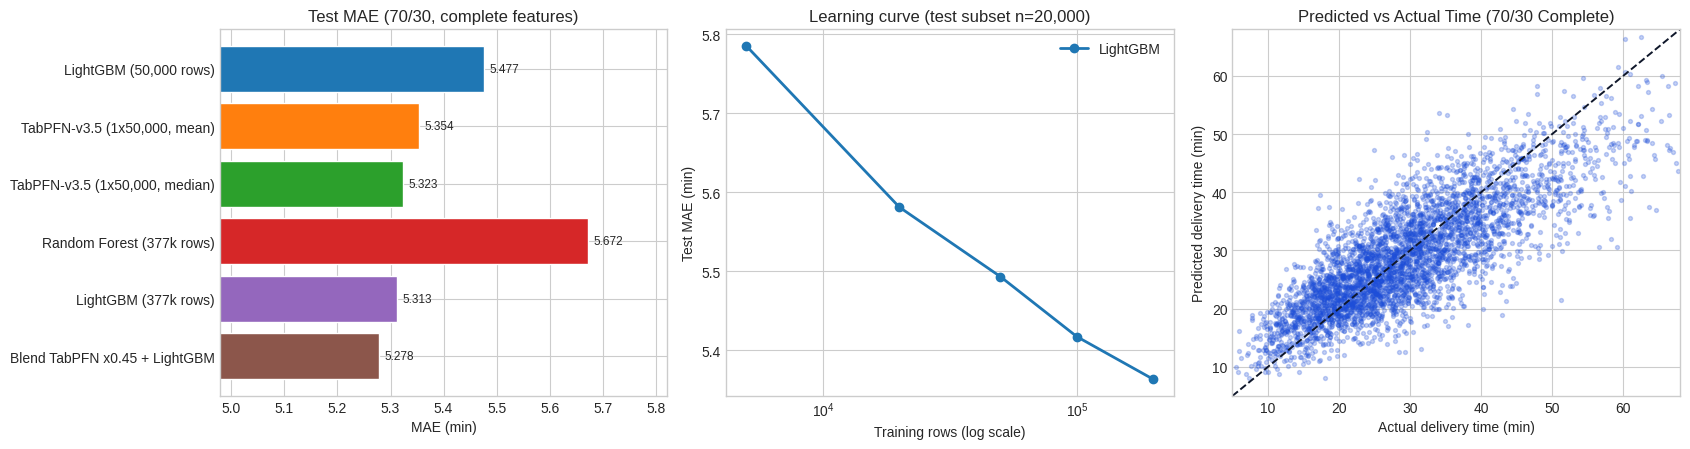

Packaged Colab artifacts to ../models/checkpoints/tabpfn_colab_artifacts.zip (2.94 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
summary_table = pd.concat([baseline_df, results_df], ignore_index=True)
summary_table = summary_table.sort_values(['split', 'stage', 'test_MAE']).reset_index(drop=True)
summary_table.to_csv(CKPT_DIR / 'colab_tabpfn_results.csv', index=False)
display(summary_table)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

colors_p = plt.cm.tab10(np.arange(len(parity_df)))
axes[0].barh(parity_df['model'], parity_df['test_MAE'], color=colors_p, edgecolor='white')
axes[0].set_xlim(float(parity_df['test_MAE'].min()) - 0.3, float(parity_df['test_MAE'].max()) + 0.15)
axes[0].invert_yaxis()
axes[0].set_title('Test MAE (70/30, complete features)')
axes[0].set_xlabel('MAE (min)')
for i, v in enumerate(parity_df['test_MAE']):
    axes[0].text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=8.5)

for name, grp in lc_df.groupby('model'):
    axes[1].plot(grp['n_train'], grp['MAE'], marker='o', lw=2, label=name)
axes[1].set_xscale('log')
axes[1].set_title(f'Learning curve (test subset n={len(te_lc):,})')
axes[1].set_xlabel('Training rows (log scale)')
axes[1].set_ylabel('Test MAE (min)')
axes[1].legend()

pred_pack = predictions_store[REFERENCE_SCENARIO]
y_t, y_p = pred_pack['y_true'], pred_pack['y_pred']
rng = np.random.default_rng(SEED)
vis_idx = rng.choice(len(y_t), size=min(4000, len(y_t)), replace=False)
axes[2].scatter(y_t[vis_idx], y_p[vis_idx], s=8, alpha=0.25, color='#1d4ed8')
lim = [5, min(140, float(np.percentile(y_t, 99.5)))]
axes[2].plot(lim, lim, ls='--', color='#0f172a', lw=1.4)
axes[2].set_xlim(lim)
axes[2].set_ylim(lim)
axes[2].set_title('Predicted vs Actual Time (70/30 Complete)')
axes[2].set_xlabel('Actual delivery time (min)')
axes[2].set_ylabel('Predicted delivery time (min)')

plt.tight_layout()
plt.savefig(CKPT_DIR / 'colab_tabpfn_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

zip_path = CKPT_DIR / 'tabpfn_colab_artifacts.zip'
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(CKPT_DIR.glob('colab_*')):
        zf.write(f, arcname=f.name)
print(f'Packaged Colab artifacts to {zip_path} ({zip_path.stat().st_size / 1e6:.2f} MB)')

if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))